In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *


## Proposition17


In [2]:
def theoretical_P_AD_from_ACGT(t, r, p, s, epsilon=None, delta=None,
                                state_idx=0, e=None):
    """
    Theoretical P(AD) from forced (AC, GT) / (GT, AC) initialization.

    Using the same convention as theoretical_P_AD_from_ADGT:
        P_AD_from_ACGT = 0.5 * P_AD_from_ADGT

    Supports both epsilon=... and e=... keyword styles.
    """
    if epsilon is None:
        epsilon = e
    if epsilon is None:
        raise ValueError('Provide epsilon (or alias e)')
    if delta is None:
        raise ValueError('Provide delta')

    p_ad_adgt = theoretical_P_AD_from_ADGT(
        t=t, r=r, p=p, s=s,
        epsilon=epsilon, d=delta,
        state_idx=state_idx,
    )
    return float(0.5 * p_ad_adgt)


def theoretical_P_GT_from_ADGT(t, r, p, s, epsilon=None, delta=None, state_idx=0, e=None):
    if epsilon is None:
        epsilon = e
    return float(1.0 - theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta, state_idx=state_idx))


def theoretical_P_GT_from_ACGT(t, r, p, s, epsilon=None, delta=None, state_idx=0, e=None):
    if epsilon is None:
        epsilon = e
    return float(1.0 - theoretical_P_AD_from_ACGT(t=t, r=r, p=p, s=s, epsilon=epsilon, delta=delta, state_idx=state_idx))


def get_aggregate_bounds_prop17(t=1, r=0.7, p=0.2, s=0, epsilon=0.1, delta=0.6):
    """
    Proposition 17 / App. B.3 bounds for BoA(pi^GT):
        lower = (2 + 4*B_hat)/16
        upper = (7 + 4*B_hat)/16
    where B_hat = BoA(pi^GT | (AD,GT)).
    """
    b_hat = theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, epsilon=epsilon, delta=delta)
    return (2.0 + 4.0 * b_hat) / 16.0, (7.0 + 4.0 * b_hat) / 16.0


def theoretical_C_hat_from_ACGT(t, r, p, s, epsilon=None, delta=None, e=None):
    """
    Literal C-hat from Appendix B.3 for (AC, GT):

        C_hat = min{a,b}/a - 0.5 * min{a,b}/max{a,b}

    with
        a = Delta q_2^{AC}(BC)
        b = Delta q_1^{GT}(A1D)

    Conventions used here (as clarified):
      - ADvsAC: AD is BR to AC, and "you are playing AC"
      - GTvsGT: GT is BR to GT
      - BC -> idx 0, A1D -> idx 1
      - Delta q uses the same code convention: q[0] - q[1]
    """
    if epsilon is None:
        epsilon = e
    if epsilon is None:
        raise ValueError('Provide epsilon (or alias e)')
    if delta is None:
        raise ValueError('Provide delta')

    # a = Delta q_2^{AC}(BC)
    q_ac_bc = QvaluesADvsAC(t, r, p, s, epsilon, delta)[0]
    a = q_ac_bc[0] - q_ac_bc[1]

    # b = Delta q_1^{GT}(A1D)
    q_gt_a1d = QvaluesGTvsGT(t, r, p, s, epsilon, delta)[1]
    b = q_gt_a1d[0] - q_gt_a1d[1]

    m = min(a, b)
    M = max(a, b)

    if a == 0 or M == 0:
        return float('nan')

    c_hat = (m / a) - 0.5 * (m / M)
    return float(c_hat)



## reading results from simulations


In [3]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_08_05 = pd.read_csv('../results/results_vect_ADGT_0.8_0.5_more_e.csv')
df_07_02 = pd.read_csv('../results/results_vect_ADGT_0.7_0.2_more_e.csv')
df_08_05_uniform = pd.read_csv('../results/results_vect_uniform_0.8_0.5_more_e.csv')
df_07_02_uniform = pd.read_csv('../results/results_vect_uniform_0.7_0.2_more_e.csv')



In [4]:
df_2000_0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/2000_0702.csv')
df_2000_0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/2000_0805.csv')


In [5]:
df_ACGT0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACGT.csv')
df_ACGT0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACGT0702.csv')
df_ADGT0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ADGT.csv')[:225]
df_ADGT0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ADGT.csv')[225:]


In [6]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df




In [7]:
#columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
#pair_combinations = list(itertools.combinations(columns, 2))


In [8]:
#heatmap_3d_voxels(df_08_05, 'delta', 'lambda', 'alpha', value='P_AD')
#heatmap_3d_voxels(df_07_02, 'delta', 'lambda', 'alpha', value='P_AD')


In [9]:
#interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= False)


In [10]:
#heatmap_mean(df, 'delta', 'e', 'P_AD')


In [11]:
def filter_for_plot(df, na = 5, nl = 8):
    alphas = np.sort(df['alpha'].unique())
    selected = alphas[np.linspace(0, len(alphas) - 1, na).astype(int)]
    lambdas = np.sort(df['lambda'].unique())
    selected_l = lambdas[np.linspace(0, len(lambdas) - 1, nl).astype(int)]
    stric_s = selected_l[:-3]
    df_filtered = df[df['alpha'].isin(selected)]
    df_filtered = df_filtered[df_filtered['lambda'].isin(stric_s)]
    return df_filtered


In [12]:
df_filtered = filter_for_plot(df_07_02, na = 5, nl = 8)
print('alpha values:',df_filtered['alpha'].unique())
print('lambda values:', df_filtered['lambda'].unique())


alpha values: [0.01  0.258 0.505 0.753 1.   ]
lambda values: [0.01  0.092 0.216 0.34  0.422]


In [13]:
df_filtered.M.value_counts()


M
20     375
100    375
500    300
Name: count, dtype: int64

## Uniform Initialization


In [14]:
from basin import *


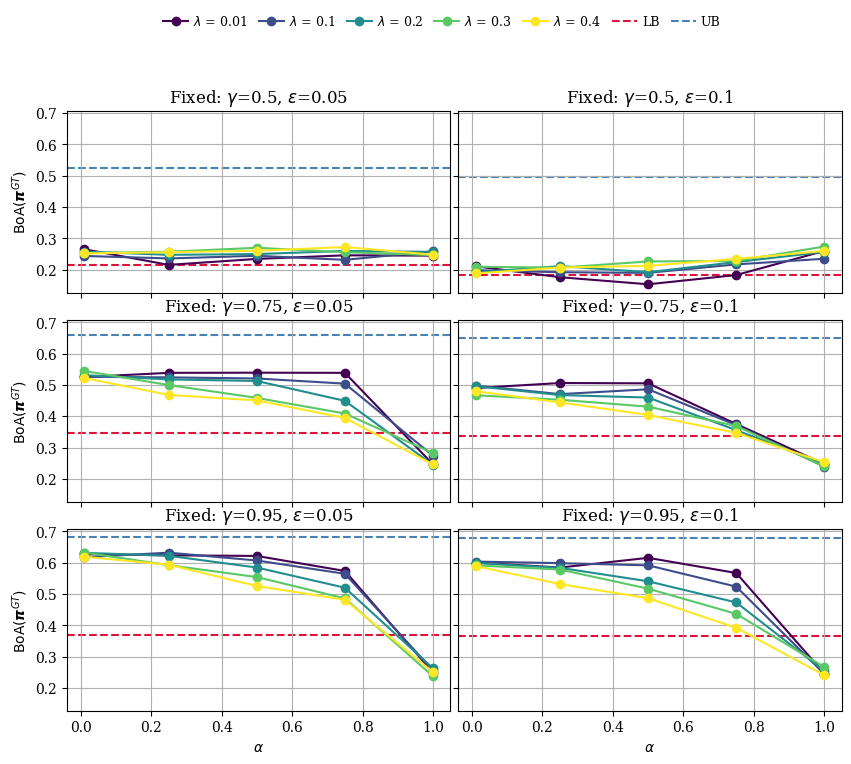

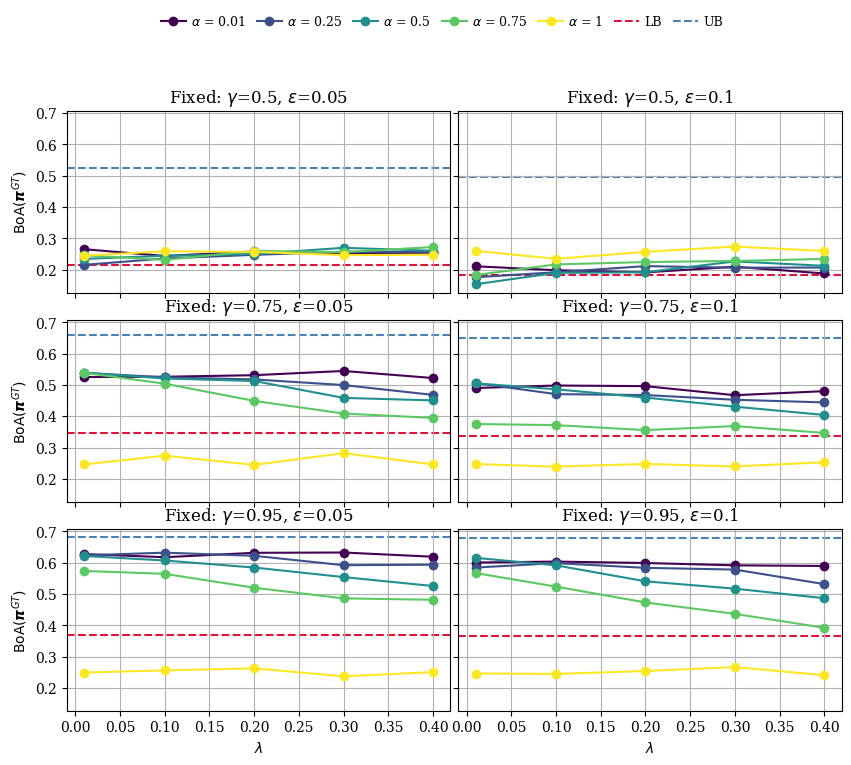

In [15]:
#df_07_02_uniform_filtered = filter_for_plot(df_07_02_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'

t, r, p, s = 1, 0.7, 0.2, 0
theoretical_bounds = [get_aggregate_bounds_prop17(t=t, r=r, p=p, s=s, epsilon=ps['e'], delta=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")
plot_multiple_panels(df_2000_0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")


In [16]:
e, delta = 0.05,0.95
t, r, p, s = 1, 0.8, 0.5, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)


(np.float64(0.3371250000000001), np.float64(0.6496250000000001))

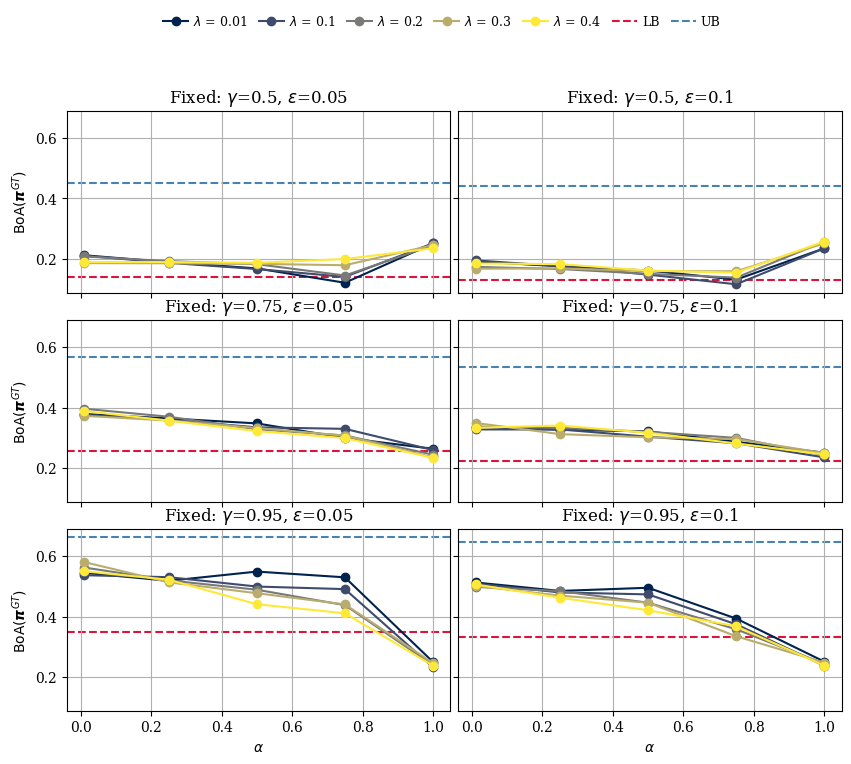

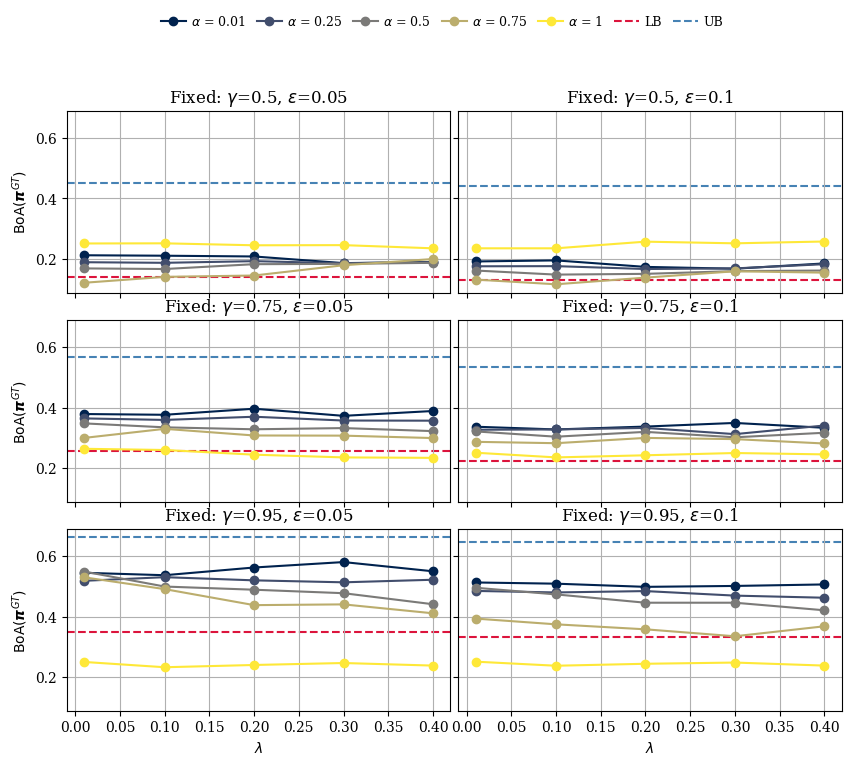

In [17]:
#df_08_05_uniform_filtered = filter_for_plot(df_08_05_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_GT'

t, r, p, s = 1, 0.8, 0.5, 0
theoretical_bounds = [get_aggregate_bounds_prop17(t=t, r=r, p=p, s=s, epsilon=ps['e'], delta=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")
plot_multiple_panels(df_2000_0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")


## ADGT plots


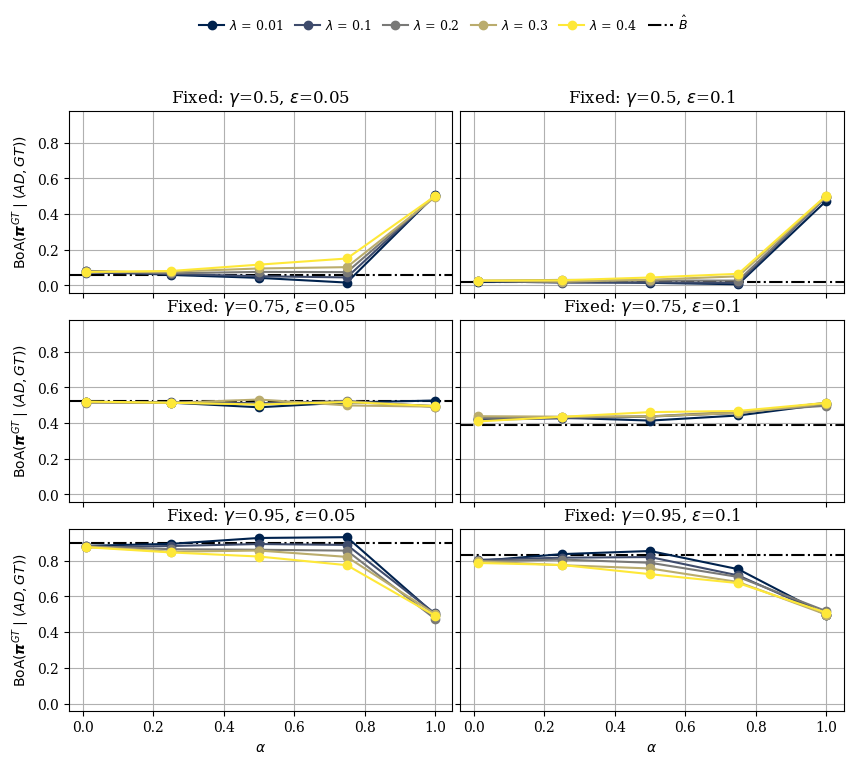

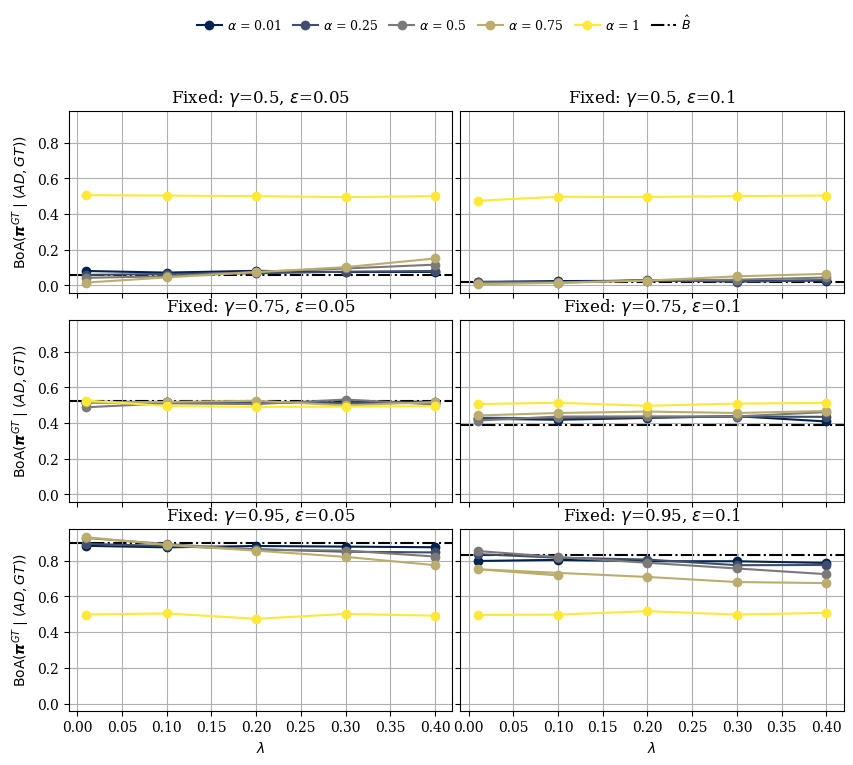

In [18]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_GT'

t, r, p, s = 1, 0.8, 0.5, 0
from MultiAgent.basin import theoretical_P_AD_from_ADGT

theoretical_per_panel = [theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
theoretical_per_panel_c_s = [theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_ADGT0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c_s, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")
plot_multiple_panels(df_ADGT0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c_s, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")


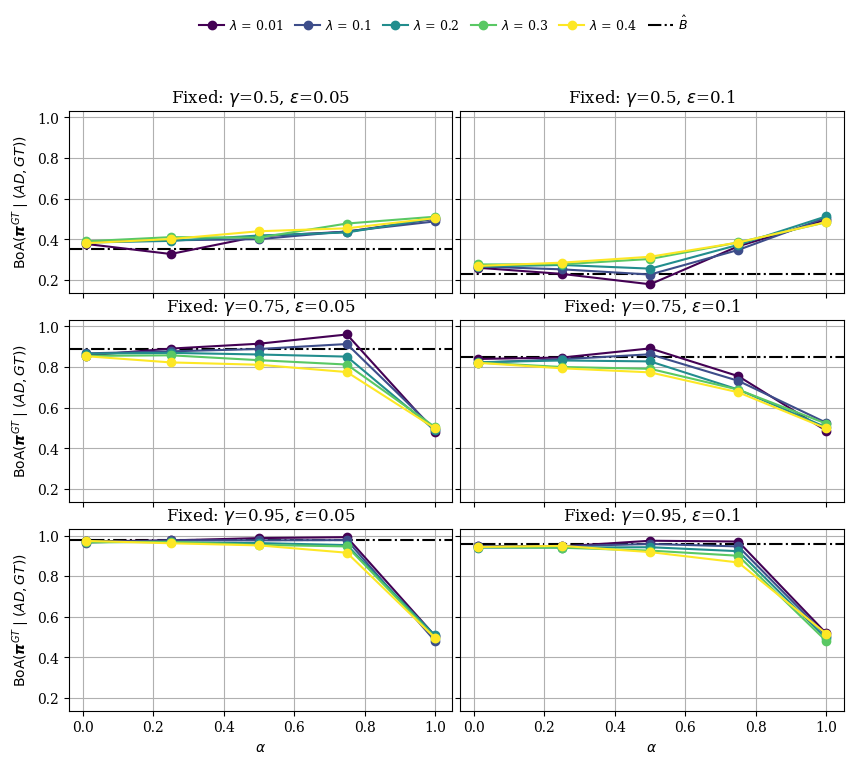

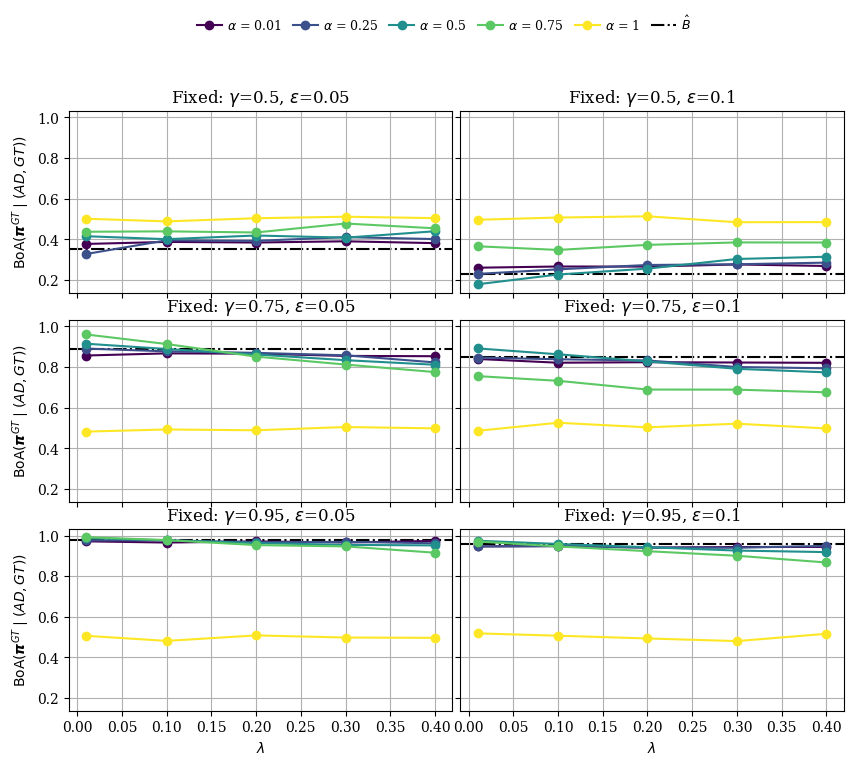

In [19]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

m=2000
y = 'P_GT'
from MultiAgent.basin import theoretical_P_AD_from_ADGT
theoretical_per_panel_c = [theoretical_P_GT_from_ADGT(t=1, r=0.7, p=0.2, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_ADGT0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=m, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")
plot_multiple_panels(df_ADGT0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=m, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")


## ACGT Plots


In [20]:
from MultiAgent.basin import theoretical_P_AD_from_ADGT


In [21]:
def theoretical_P_AD_from_ACGT(t, r, p, s, epsilon=None, delta=None,
                                state_idx=0, e=None):
    """
    Theoretical P(AD) from forced (AC, GT) / (GT, AC) initialization.

    Using the same convention as theoretical_P_AD_from_ADGT:
        P_AD_from_ACGT = 0.5 * P_AD_from_ADGT

    Supports both epsilon=... and e=... keyword styles.
    """
    if epsilon is None:
        epsilon = e
    if epsilon is None:
        raise ValueError('Provide epsilon (or alias e)')
    if delta is None:
        raise ValueError('Provide delta')

    p_ad_adgt = theoretical_P_AD_from_ADGT(
        t=t, r=r, p=p, s=s,
        epsilon=epsilon, d=delta,
        state_idx=state_idx,
    )
    return float(0.5 * p_ad_adgt)


def theoretical_P_GT_from_ADGT(t, r, p, s, epsilon=None, delta=None, state_idx=0, e=None):
    if epsilon is None:
        epsilon = e
    return float(1.0 - theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta, state_idx=state_idx))


def theoretical_P_GT_from_ACGT(t, r, p, s, epsilon=None, delta=None, state_idx=0, e=None):
    if epsilon is None:
        epsilon = e
    return float(1.0 - theoretical_P_AD_from_ACGT(t=t, r=r, p=p, s=s, epsilon=epsilon, delta=delta, state_idx=state_idx))


def get_aggregate_bounds_prop17(t=1, r=0.7, p=0.2, s=0, epsilon=0.1, delta=0.6):
    """
    Proposition 17 / App. B.3 bounds for BoA(pi^GT):
        lower = (2 + 4*B_hat)/16
        upper = (7 + 4*B_hat)/16
    where B_hat = BoA(pi^GT | (AD,GT)).
    """
    b_hat = theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, epsilon=epsilon, delta=delta)
    return (2.0 + 4.0 * b_hat) / 16.0, (7.0 + 4.0 * b_hat) / 16.0


def theoretical_C_hat_from_ACGT(t, r, p, s, epsilon=None, delta=None, e=None):
    """
    Literal C-hat from Appendix B.3 for (AC, GT):

        C_hat = min{a,b}/a - 0.5 * min{a,b}/max{a,b}

    with
        a = Delta q_2^{AC}(BC)
        b = Delta q_1^{GT}(A1D)

    Conventions used here (as clarified):
      - ADvsAC: AD is BR to AC, and "you are playing AC"
      - GTvsGT: GT is BR to GT
      - BC -> idx 0, A1D -> idx 1
      - Delta q uses the same code convention: q[0] - q[1]
    """
    if epsilon is None:
        epsilon = e
    if epsilon is None:
        raise ValueError('Provide epsilon (or alias e)')
    if delta is None:
        raise ValueError('Provide delta')

    # a = Delta q_2^{AC}(BC)
    q_ac_bc = QvaluesADvsAC(t, r, p, s, epsilon, delta)[0]
    a = q_ac_bc[0] - q_ac_bc[1]

    # b = Delta q_1^{GT}(A1D)
    q_gt_a1d = QvaluesGTvsGT(t, r, p, s, epsilon, delta)[1]
    b = q_gt_a1d[0] - q_gt_a1d[1]

    m = min(a, b)
    M = max(a, b)

    if a == 0 or M == 0:
        return float('nan')

    c_hat = (m / a) - 0.5 * (m / M)
    return float(c_hat)



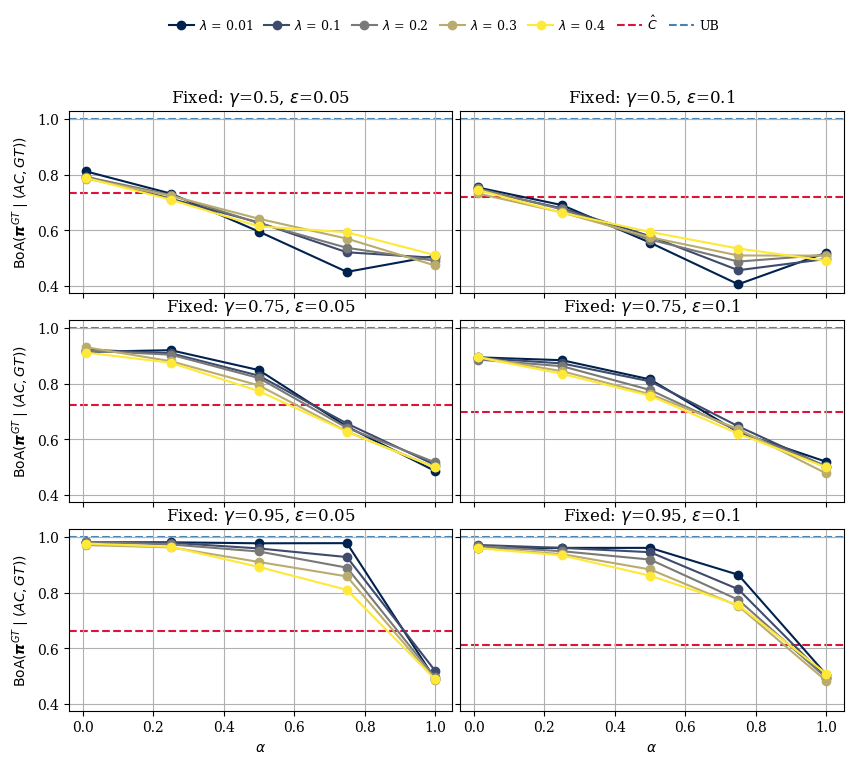

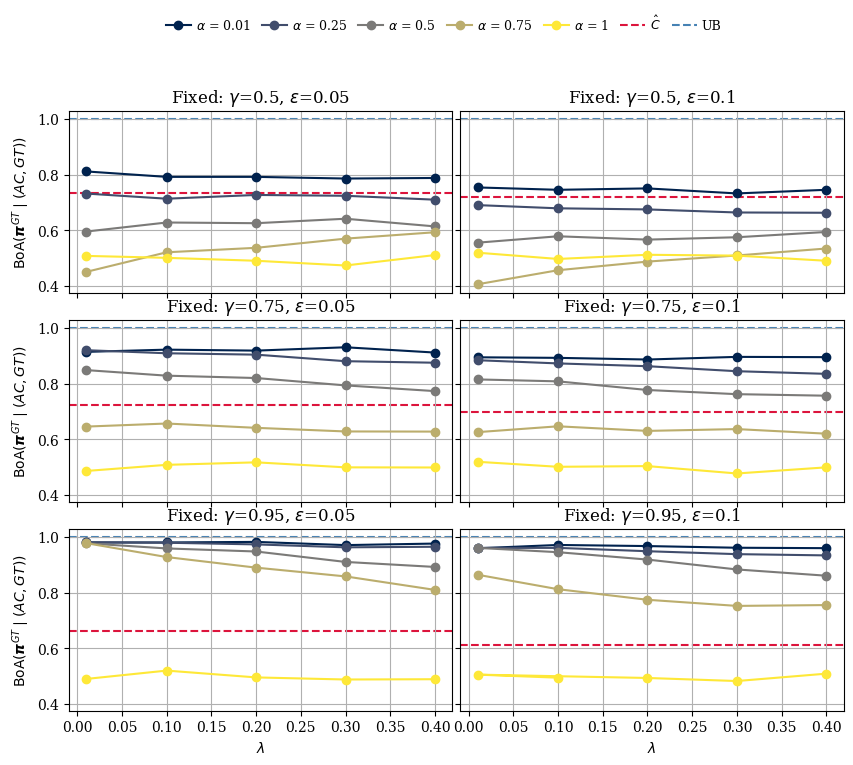

In [22]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'
t, r, p, s = 1, 0.8, 0.4, 0

# Latex reference (ACGT): C-hat <= BoA(pi^GT | (AC,GT)) <= 1
theoretical_bounds_acgt = [
    (theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps['delta'], epsilon=ps['e']), 1.0)
    for ps in param_sets
]

plot_multiple_panels(
    df_ACGT0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y,
    m=2000, use_same_scale=True, cmap='cividis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)
plot_multiple_panels(
    df_ACGT0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y,
    m=2000, use_same_scale=True, cmap='cividis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)


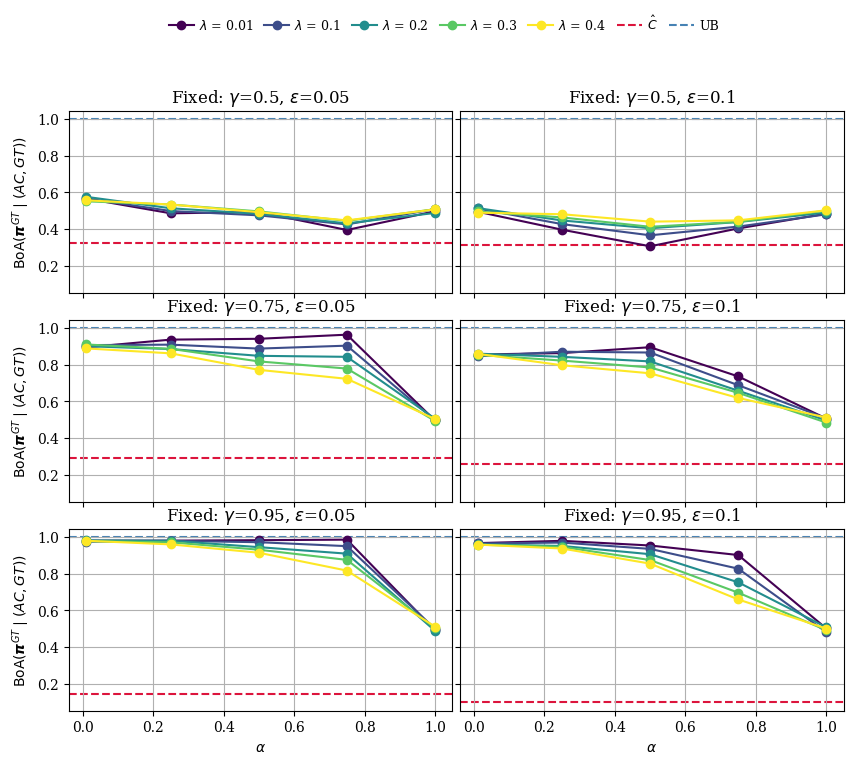

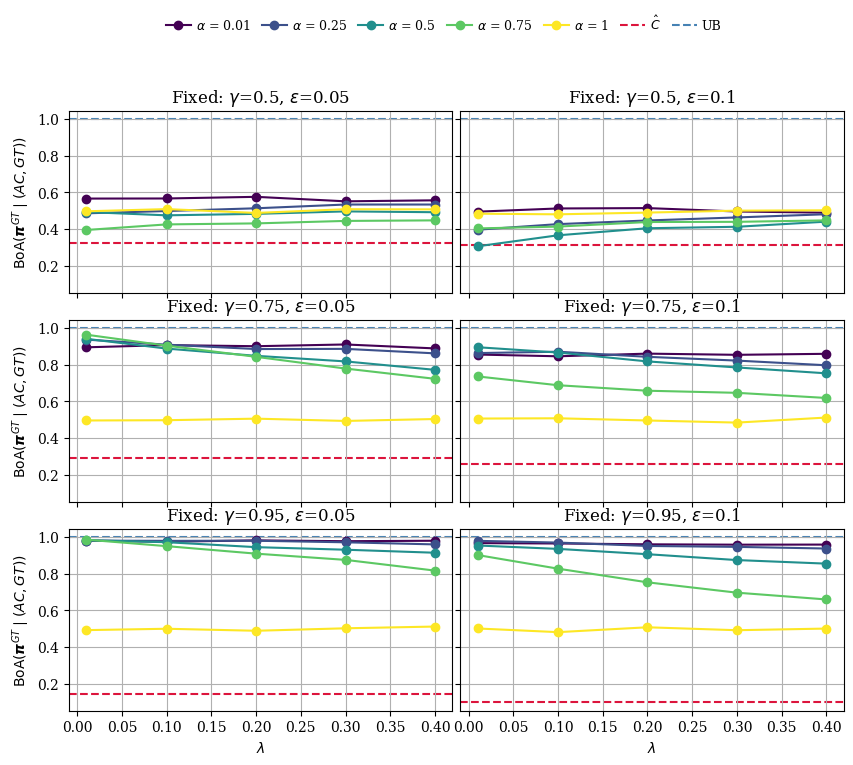

In [23]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'
t, r, p, s = 1, 0.7, 0.2, 0

# Latex reference (ACGT): C-hat <= BoA(pi^GT | (AC,GT)) <= 1
theoretical_bounds_acgt = [
    (theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps['delta'], epsilon=ps['e']), 1.0)
    for ps in param_sets
]

plot_multiple_panels(
    df_ACGT0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y,
    m=2000, use_same_scale=True, cmap='viridis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)
plot_multiple_panels(
    df_ACGT0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y,
    m=2000, use_same_scale=True, cmap='viridis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)
